# Phase 1

## 10.26.26 | diversity of samples compared to controls

In [1]:
# Load packages
suppressPackageStartupMessages({
    library(phyloseq)
    library(tidyverse)
    library(data.table)
    library(pals)
})
    
options(repr.plot.width=18, repr.plot.height=8)

In [2]:
# Read in phyloseq object with just phase 2 samples - decipher taxonomic assignmnet
ps_p2 <- readRDS("/scratch4/workspace/jade_fiorilla_student_uml_edu-rawseqorcc/dada2/ps_p2.rds")

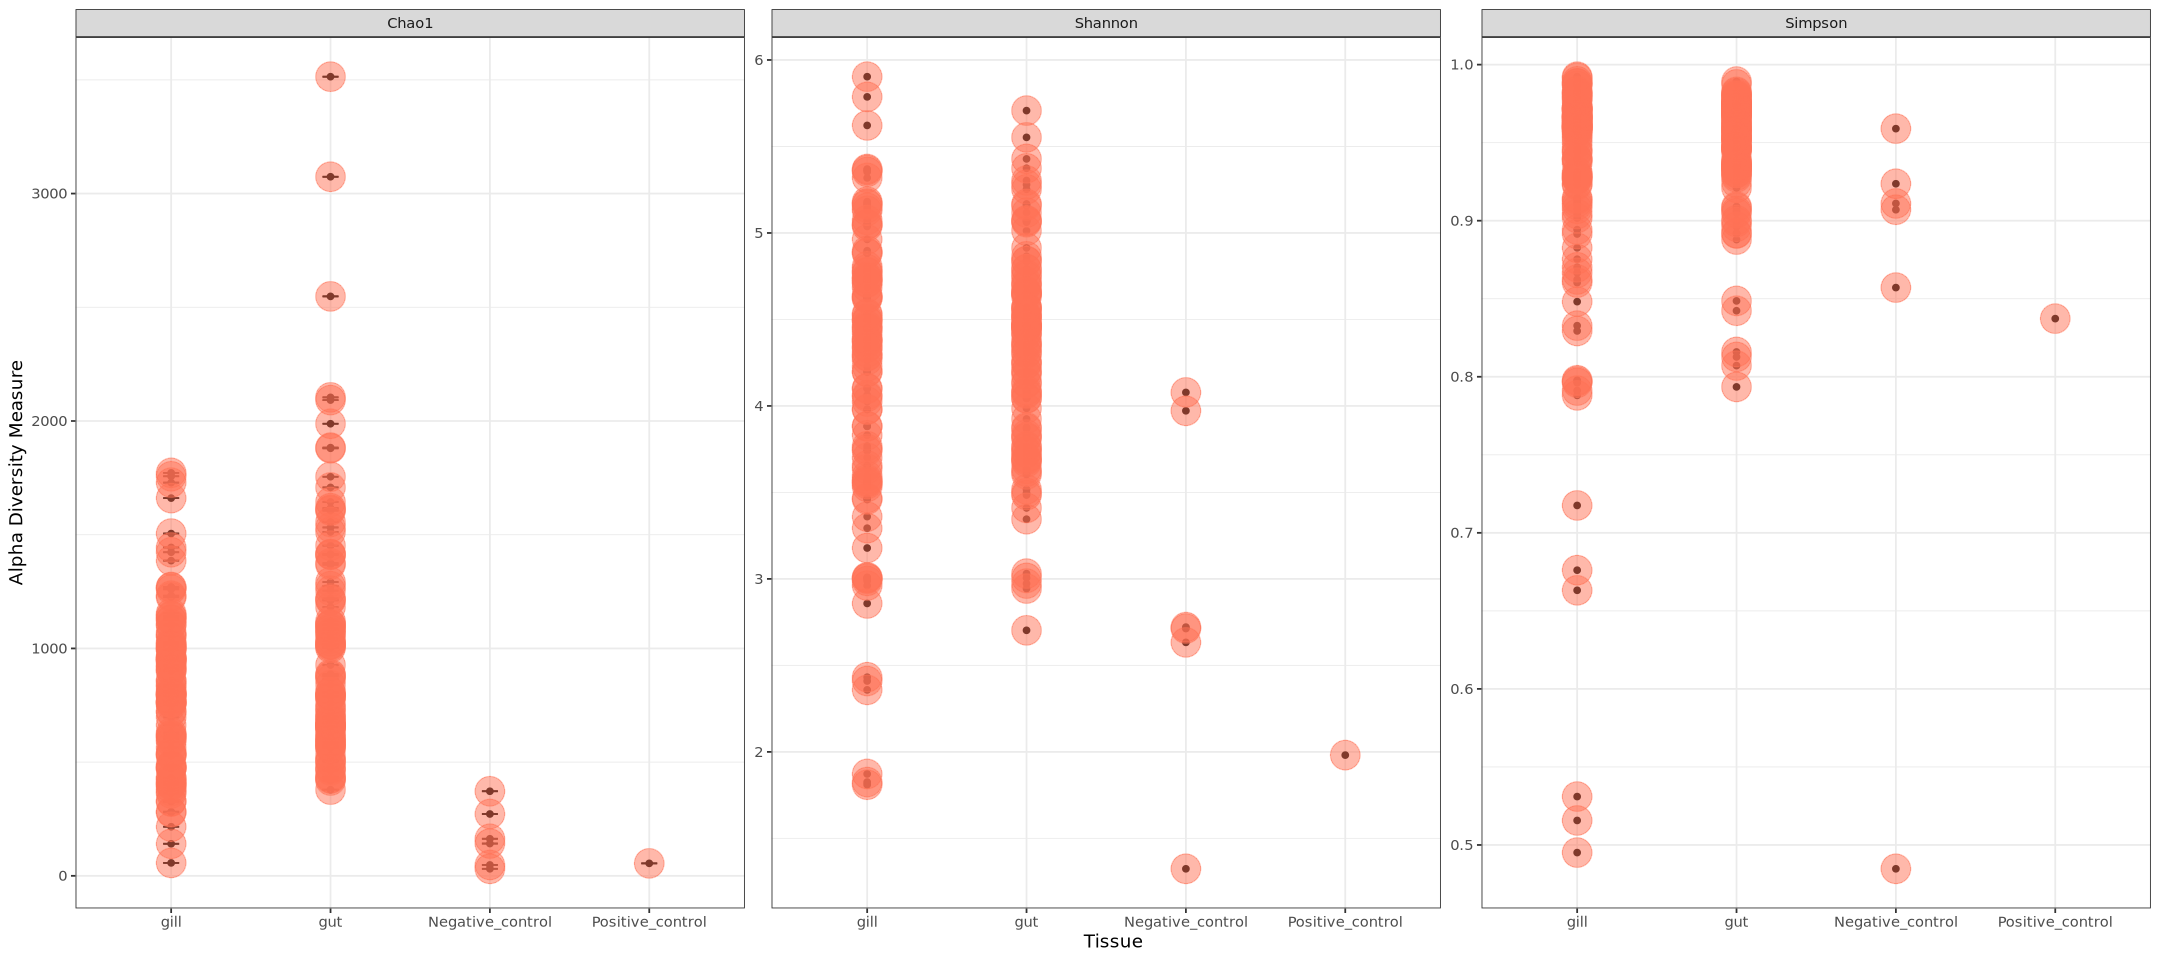

In [6]:
# Plot alpha diversity metrics
plot_richness(ps_p2, x = "Tissue", measures = c("Shannon", "Simpson", "Chao1")) +
    geom_point(size = 8, alpha = 0.5, color = "coral 1")  +
    theme_bw()

- Chao1 estimates species richness based on the number of singelton and doubleton reads, correcting for undetected species (higher index = higher diversity)
- Shannon considers both richness and evenness, capturing how difficult it is to predict the identity of a read (higher index = higher diversity)
- Simpson gets at the dominance, or the probability of two random reads being the same (higher index = lower diversity)

In [7]:
# Aggregate taxa at the phylum, order, and family levels
ps_phyla <- tax_glom(ps_p2, taxrank = "phylum")
ps_order <- tax_glom(ps_p2, taxrank = "order")
ps_family <- tax_glom(ps_p2, taxrank = "family")

In [8]:
# List of the top 20 most abundant families
phyla20 <- names(sort(taxa_sums(ps_phyla), decreasing=TRUE))[1:20]

# Only include those families in the phyloseq object
ps_phyla <- prune_taxa(phyla20, ps_phyla)

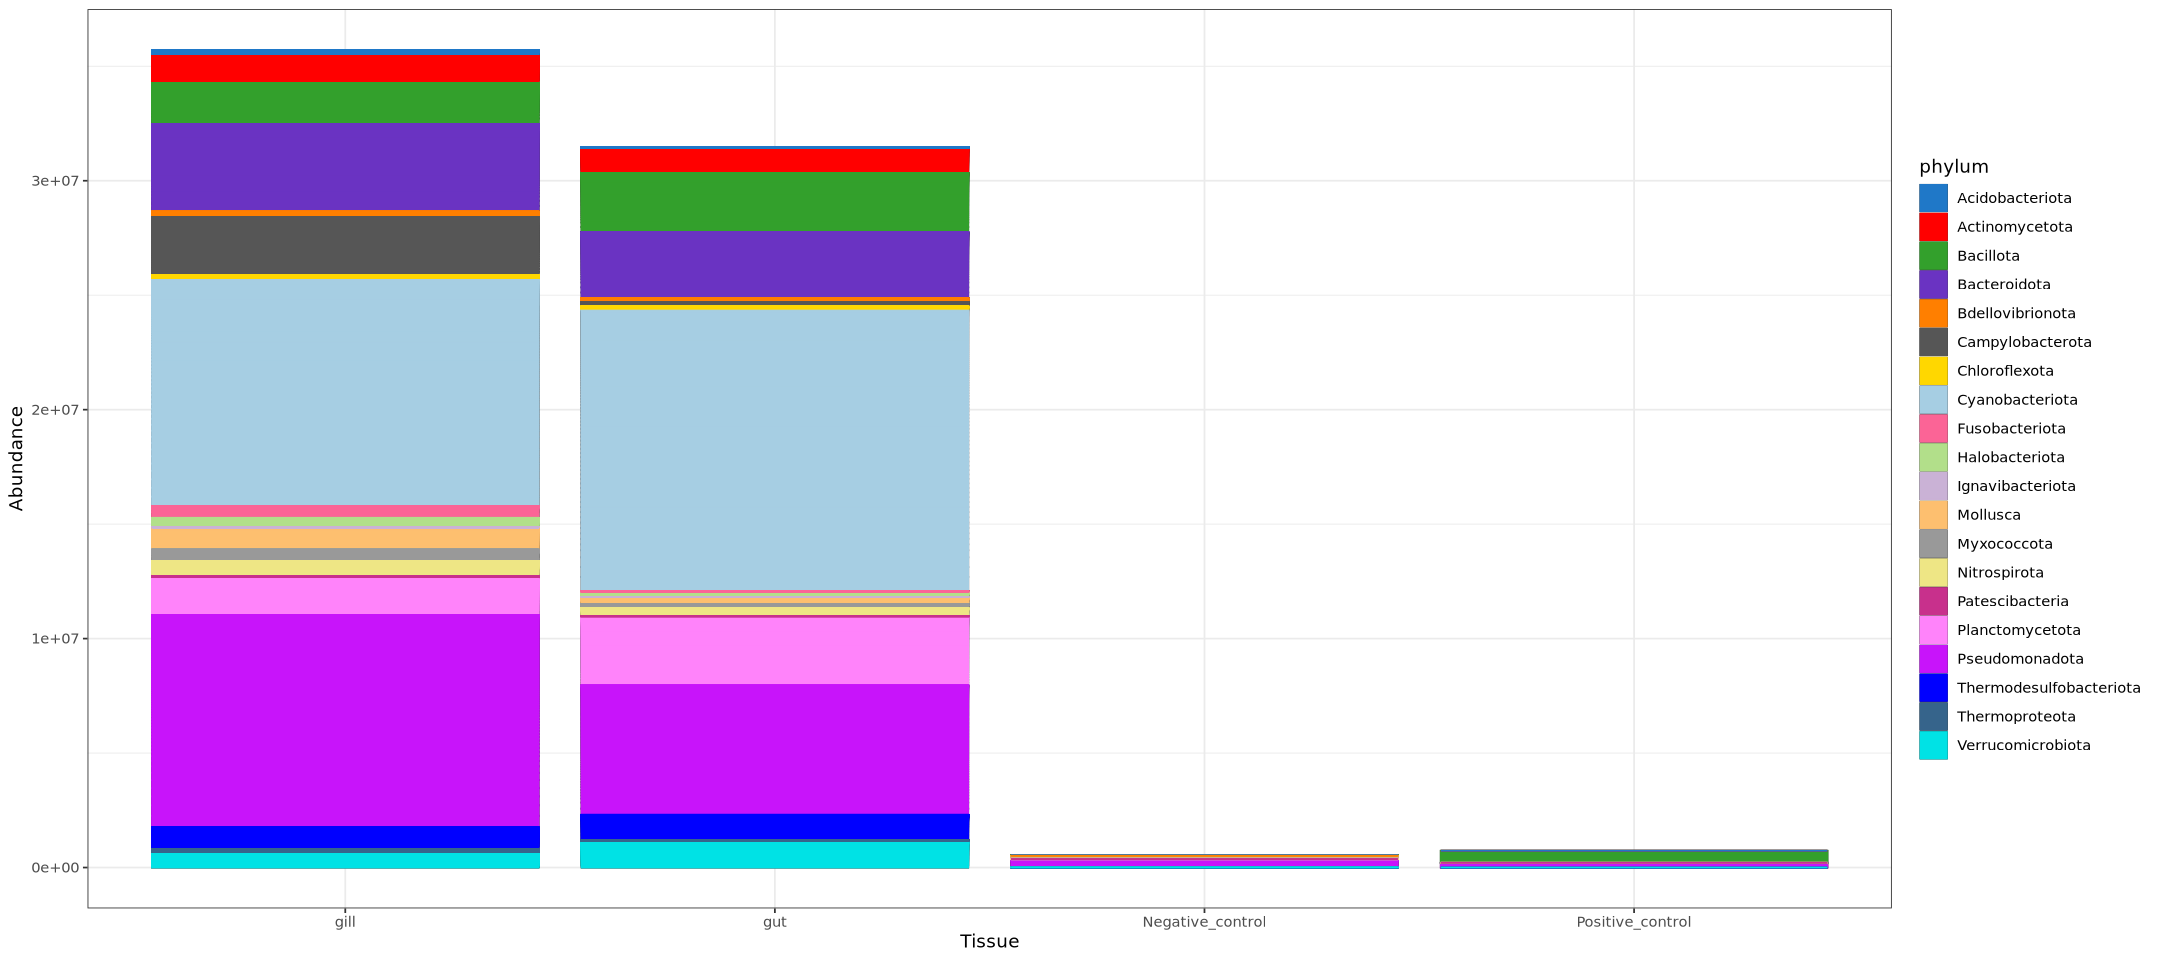

In [37]:
plot_bar(ps_phyla, x="Tissue", fill = "phylum") +
    geom_bar(aes(color=phylum, fill=phylum), stat="identity", position="stack") +
    scale_fill_manual(values = as.vector(cols25())) +
    scale_color_manual(values = as.vector(cols25())) +
    theme_bw()